In [4]:
from photutils.detection import DAOStarFinder
from astropy.stats import sigma_clipped_stats
from photutils.aperture import CircularAperture
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile

from matplotlib import pyplot as plt
import numpy as np

#import ccdproc

from astropy.nddata import CCDData
import astropy.units as u
from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

In [5]:
def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='gray_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)
    
def add_stars(xstars,ystars,radius=20,color='r',ax=None):
    ''' this will add circles at the location of xstars,ystars '''
    if ax is None:
        ax = plt.gca()
    allcircles=[]
    #The zip function takes iterables (e.g. lists or arrays) and groups them into tuples that contain 
    #matched pairs of each input, e.g [(x,y)]
    for x,y in zip(xstars,ystars):
        c = plt.Circle((x,y),radius,color=color,fill=False)
        #allcircles.append(c)
        ax.add_artist(c)

Text(0.5, 1.0, 'M3 G-band image')

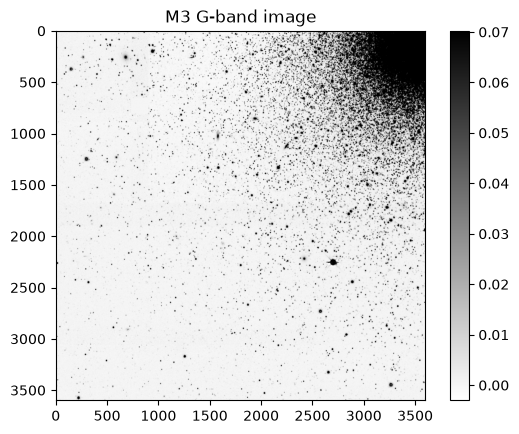

In [7]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('M3 G-band image.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M3 G-band image")

Text(0.5, 1.0, 'M3 R-band image')

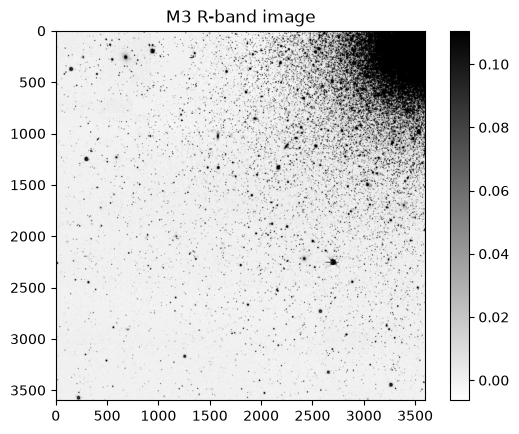

In [8]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('M3 R-band image.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M3 R-band image")

In [9]:
from astropy.io import fits
from photutils.psf import fit_fwhm

def calc_fwhm(imagefilename, xyposlist):
    '''
    This function takes as input an image file name and a list of star pixel coordinates 
    and prints the FWHM for each star.  

    Stars should be bright, unsaturated, and isolated.

    INPUTS: 
    imagefilename: a string containing the image file name

    xyposlist: a list of x and y coordinates of the form [(x1,y1), (x2,y2)]
    This can contain an arbitrary number of stars.

    OUTPUT:
    fwhmlist: a list of FWHM
    '''
    image = fits.getdata(imagefilename)
    
    #use the photutils.psf.fit_fwhm function to fit a 2D PSF to the stars.
    fwhm = fit_fwhm(
        image,
        xypos=xyposlist,
        fwhm=4.0,        # initial guess, pixels
        fit_shape=21
    )
    print(f'The FWHM of the stars in {imagefilename} in pixels are {fwhm}')
    return(fwhm)

In [12]:
# Calculate FWHM for M3 G-band

M3Gstars = [(2096,1627),(1877,1742),(1952,1973),(2091,1964),(1869,1875)]

M3G_fwhm = calc_fwhm('M3 G-band image.fits', M3Gstars)

print("G-band FWHM:", M3G_fwhm)
print("Mean G-band FWHM:", np.mean(M3G_fwhm))
print("Median G-band FWHM:", np.median(M3G_fwhm))

The FWHM of the stars in M3 G-band image.fits in pixels are [4.89523647 5.35342197 4.96516592 5.03978985 5.43163367]
G-band FWHM: [4.89523647 5.35342197 4.96516592 5.03978985 5.43163367]
Mean G-band FWHM: 5.137049578310174
Median G-band FWHM: 5.039789853288136


In [14]:
# Calculate FWHM for M3 R-band

M3Rstars = [(1734,1745),(1952,1975),(1998,1591),(2119,1723),(2095,1943)]

M3R_fwhm = calc_fwhm('M3 R-band image.fits', M3Rstars)

print("R-band FWHM:", M3R_fwhm)
print("Mean R-band FWHM:", np.mean(M3R_fwhm))
print("Median R-band FWHM:", np.median(M3R_fwhm))

The FWHM of the stars in M3 R-band image.fits in pixels are [4.11126173 4.25709579 4.11431064 4.08772866 4.12383925]
R-band FWHM: [4.11126173 4.25709579 4.11431064 4.08772866 4.12383925]
Mean R-band FWHM: 4.138847214530186
Median R-band FWHM: 4.114310639603594
